# 01 - Exploring the AI Incident Database

First look at the data: how many incidents, which years, what kind of incidents.

## 1. Load the data

In [1]:
import pandas as pd

df = pd.read_csv("data/mongodump_full_snapshot/incidents.csv")

## 2. How big is it?

In [2]:
print("Rows and columns:", df.shape)
print(df.columns.tolist())

Rows and columns: (1786, 9)
['_id', 'incident_id', 'date', 'reports', 'Alleged deployer of AI system', 'Alleged developer of AI system', 'Alleged harmed or nearly harmed parties', 'description', 'title']


## 3. First 5 rows

In [3]:
df[["incident_id", "date", "title"]].head()

,incident_id,date,title
0,23,2017-11-08,Las Vegas Self-Driving Bus Involved in Accident
1,4,2018-03-18,Uber AV Killed Pedestrian in Arizona
2,1,2015-05-19,Google’s YouTube Kids App Presents Inappropria...
3,18,2015-04-04,Gender Biases of Google Image Search
4,12,2016-07-21,Common Biases of Vector Embeddings


## 4. Make the dates real dates

In [4]:
df["date"] = pd.to_datetime(df["date"])

print("Earliest incident:", df["date"].min())
print("Latest incident:", df["date"].max())

Earliest incident: 1983-09-26 00:00:00
Latest incident: 2026-10-30 00:00:00


## My notes

- How many incidents:
- Earliest and latest date:
- What I noticed:
- 1,786 incidents with 9 columns ✅
Earliest: 26 September 1983. That’s the famous Soviet nuclear false alarm: an early-warning computer system wrongly reported US missiles, and one officer, Stanislav Petrov, decided not to trust it. It isn’t modern AI, but it’s in the database because it’s an automated system that nearly caused a disaster. It’s a nice example for your theory of change too: an early-warning system that gave a false alarm.
Latest: 30 October 2026, so the data is very up to date ✅

year
1983      1
1992      1
1996      1
1998      1
1999      1
2003      4
2006      1
2007      1
2008      3
2009      2
2010      1
2011      3
2012      8
2013      6
2014     13
2015     24
2016     41
2017     52
2018     46
2019     45
2020     91
2021     80
2022    109
2023    179
2024    313
2025    463
2026    296
Name: count, dtype: int64


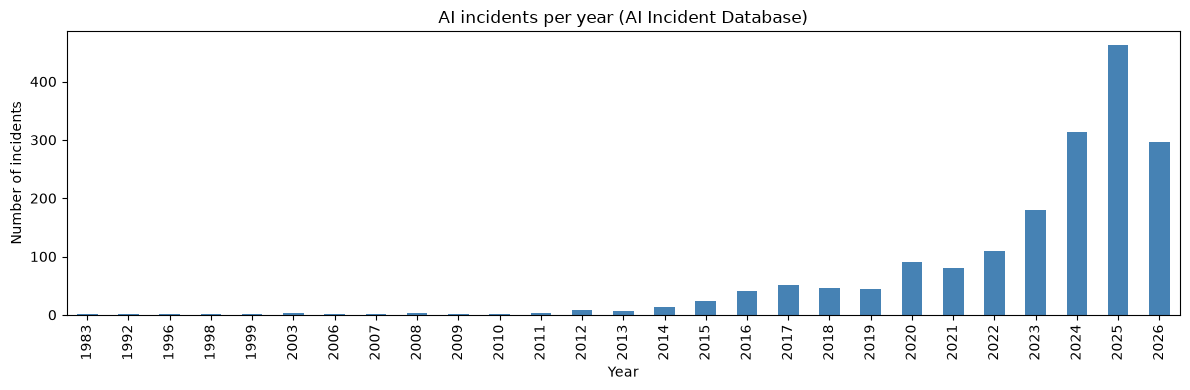

In [6]:
import matplotlib.pyplot as plt

df["year"] = df["date"].dt.year

per_year = df["year"].value_counts().sort_index()
print(per_year)

per_year.plot(kind="bar", figsize=(12, 4), color="steelblue")
plt.title("AI incidents per year (AI Incident Database)")
plt.xlabel("Year")
plt.ylabel("Number of incidents")
plt.tight_layout()
plt.show()


In [ ]:
## my notes
1. What happens after 2020?
Look at 2020 → 2025: 91 → 80 → 109 → 179 → 313 → 463. Roughly how many times bigger is 2025 than 2020?

2. Is 2026 really lower?
2026 has 296 so far. The data ends on 30 October 2026, so how many months of 2026 are missing? If incidents kept coming at the same speed, about how many would the full year have?

(Hint: 296 ÷ 10 months ≈ ? per month, then × 12)

3. Is AI really causing more harm, or is something else going on?
Think of your TLB work. Imagine that in 2015 only a few farmers knew how to report blight, but by 2025 every farmer has a phone app to report it. The reports would go up a lot even if the disease stayed the same.

Some things to think about:

When did ChatGPT come out, and did it make journalists write more about AI?
The AI Incident Database itself started around 2020. Could that change how many incidents get recorded?
Are there simply more AI systems in use now?

In [7]:
per_year = df["year"].value_counts().sort_index()
per_year = per_year.reindex(range(2010, 2027), fill_value=0)

In [8]:
mit = pd.read_csv("data/mongodump_full_snapshot/classifications_MIT.csv")
print("MIT rows:", len(mit))

both = df.merge(mit, left_on="incident_id", right_on="Incident ID", how="inner")
print("Incidents with a risk type:", len(both))

both["Risk Domain"].value_counts()

MIT rows: 1498
Incidents with a risk type: 1498


Risk Domain
4. Malicious Actors & Misuse                      566
7. AI system safety, failures, and limitations    314
1. Discrimination and Toxicity                    244
3. Misinformation                                 196
2. Privacy & Security                             112
5. Human-Computer Interaction                      42
6. Socioeconomic & Environmental Harms             24
Name: count, dtype: int64

Risk Domain  1. Discrimination and Toxicity  2. Privacy & Security  \
year                                                                 
2015                                      7                      3   
2016                                     16                      1   
2017                                     16                      9   
2018                                     14                      5   
2019                                     16                      6   
2020                                     32                      5   
2021                                     18                      5   
2022                                     25                     10   
2023                                     24                     12   
2024                                     30                     17   
2025                                     25                     24   

Risk Domain  3. Misinformation  4. Malicious Actors & Misuse  \
year                     

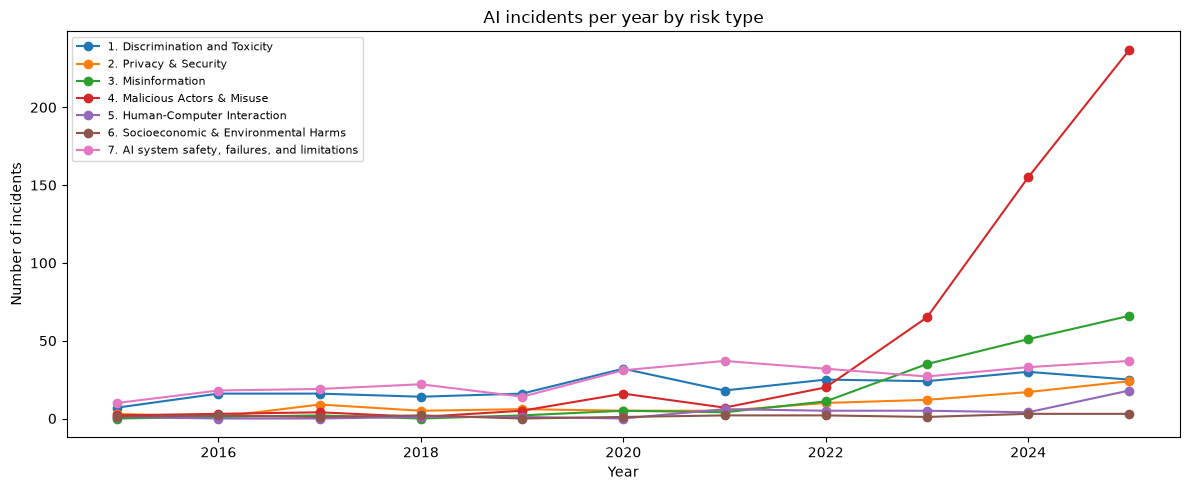

In [9]:
by_type = pd.crosstab(both["year"], both["Risk Domain"])
by_type = by_type.loc[2015:2025]
print(by_type)

by_type.plot(figsize=(12, 5), marker="o")
plt.title("AI incidents per year by risk type")
plt.xlabel("Year")
plt.ylabel("Number of incidents")
plt.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

In [10]:
labelled_ids = set(mit["Incident ID"])
df["has_label"] = df["incident_id"].isin(labelled_ids)

label_rate = df.groupby("year")["has_label"].mean().loc[2015:2026]
print((label_rate * 100).round(0))


year
2015    100.0
2016    100.0
2017     98.0
2018     98.0
2019     98.0
2020     99.0
2021     99.0
2022     96.0
2023     94.0
2024     94.0
2025     89.0
2026     34.0
Name: has_label, dtype: float64
